<center><h1>Open-CV Image Inpainting Notebook</h1>
<h2>Matthias Bartolo</h2>

</center>

## Image Inpainting Methods in OpenCV

In OpenCV, image inpainting is the process of reconstructing lost or deteriorated parts of an image. This can be particularly useful for removing unwanted objects or filling in missing areas in images. OpenCV provides two main algorithms for inpainting:

### 1. Telea's Method (`cv2.INPAINT_TELEA`)

Telea's method is an inpainting algorithm based on a fast marching method. It is particularly effective for filling small areas of missing pixels and is known for producing visually pleasing results. 

**How it Works:**
- The algorithm propagates information from the known regions of the image to the unknown regions.
- It uses the surrounding pixel values to estimate the values of the missing pixels, ensuring that the inpainted area blends seamlessly with the surrounding area.
- The process involves solving the Poisson equation to maintain the gradient of the image.

**Mathematical Formulation:**
The algorithm can be described using the Poisson equation:
$$
\nabla^2 I = 0
$$
where 
- $ I $ represents the image intensity.
- The Laplacian operator $ \nabla^2 $ is used to calculate the divergence of the gradient of the image intensity.
- $ 0 $ indicates that the divergence of the gradient is zero, meaning that the gradient is constant.

The solution of this equation helps to reconstruct the inpainted area based on neighboring pixel values.

**Key Characteristics:**
- Typically produces smoother results compared to other methods.
- Works well for small regions with textures similar to their surroundings.

### 2. Navier-Stokes Based Method (`cv2.INPAINT_NS`)

The Navier-Stokes based method applies the principles of fluid dynamics to image inpainting. It simulates the behavior of fluids to propagate pixel information from the known areas into the unknown areas.

**How it Works:**
- The method uses the Navier-Stokes equations to analyze the flow of pixel information, treating pixel values like fluid particles.
- The algorithm calculates the direction and velocity of the pixel flow based on the surrounding pixel intensities, allowing for the diffusion of pixel information into the masked area.
- The approach takes into account the continuity of the image structure and helps maintain the edges of objects in the image.

**Mathematical Formulation:**
The basic Navier-Stokes equations for incompressible flow can be expressed as:
$$
\frac{\partial \mathbf{u}}{\partial t} + (\mathbf{u} \cdot \nabla) \mathbf{u} = -\nabla p + \nu \nabla^2 \mathbf{u}
$$
where:
- $ \mathbf{u} $ is the velocity field of the fluid,
- $ p $ is the pressure,
- $ \nu $ is the kinematic viscosity.

This formulation helps in modeling the pixel flow in the image, facilitating the inpainting process.

**Key Characteristics:**
- More effective for larger areas with well-defined edges.
- Can preserve sharper transitions and details better than Telea's method in some scenarios.

### Choosing Between the Methods

- **Telea's Method**: Use this for smaller areas or when you want smoother, more uniform results.
- **Navier-Stokes Method**: Opt for this when dealing with larger areas or when edge preservation is critical.

By experimenting with both methods, users can select the one that best fits their particular inpainting needs.


<h3>Package Imports</h3>

In [1]:
!pip install opencv-python numpy matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cv2
import requests
import numpy as np
from PIL import Image
from matplotlib import pyplot as plt

<h3>Defining the Inpainting Tool</h3>

In [3]:
class InpaintingTool:
    def __init__(self, image):
        self.image = image
        self.mask = np.zeros(image.shape[:2], dtype=np.uint8)
        self.drawing = False
        self.brush_size = 5

    def set_brush_size(self, size):
        self.brush_size = size

    def draw_mask(self, event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:
            self.drawing = True
            cv2.circle(self.mask, (x, y), self.brush_size, (255), -1)
        elif event == cv2.EVENT_MOUSEMOVE:
            if self.drawing:
                cv2.circle(self.mask, (x, y), self.brush_size, (255), -1)
        elif event == cv2.EVENT_LBUTTONUP:
            self.drawing = False
            cv2.circle(self.mask, (x, y), self.brush_size, (255), -1)

    def clear_mask(self):
        self.mask[:] = 0  # Clear the mask

<h3>Loading the Image</h3>

In [9]:
image_path = 'malina.jpg'  # Change this to the path of your image
# Load image if URL is provided
if image_path.startswith("http"):
    image = Image.open(requests.get(image_path, stream=True).raw)
else:
    image = Image.open(image_path)

image = np.array(image)

# Define the available options
options = {0: cv2.INPAINT_TELEA, 1: cv2.INPAINT_NS}

# Prompt the user to select the inpainting method
print("Select the inpainting method (0: Telea, 1: Navier-Stokes [Default: 0]):")

try:
    method = int(input())
    if method not in options:
        print("Invalid selection. Using default method: Telea.")
        method = options[0]
    else:
        method = options[method]
except ValueError:
    print("Invalid input. Using default method: Telea.")
    method = options[0]

# Create an instance of the inpainting tool
inpainting_tool = InpaintingTool(image)

Select the inpainting method (0: Telea, 1: Navier-Stokes [Default: 0]):


<h3>User Input for Mask Creation</h3>

In [ ]:
cv2.namedWindow('Image Inpaiting Tool')
cv2.setMouseCallback('Image Inpaiting Tool', inpainting_tool.draw_mask)

# Create trackbars for brush size
def update_brush_size(x):
    inpainting_tool.set_brush_size(x)

cv2.createTrackbar('Brush Size', 'Image Inpaiting Tool', inpainting_tool.brush_size, 50, update_brush_size)

# Define the text instructions
instructions = [
    "Instructions:",
    "Press 'i' to inpaint the selected area",
    "Press 'c' to clear the mask",
    "Press 'q' to exit without saving",
    "Adjust brush size using the trackbar",
    "Brush Size: {}".format(inpainting_tool.brush_size)
]

while True:
    display_image = image.copy()
    
    # Create a mask with grey color only on the brushed area
    mask_color = np.zeros_like(image)
    mask_color[inpainting_tool.mask == 255] = [192, 192, 192]  # Grey color for the mask

    # Blend the grey mask with the original image only on the brushed area
    alpha = 0.5  # Transparency level
    cv2.addWeighted(display_image, 1, mask_color, alpha, 0, display_image)
    
    # Overlay the mask
    display_image[inpainting_tool.mask == 255] = [192, 192, 192]  # Ensure mask is grey
    
    # Update brush size in instructions
    instructions[5] = "Brush Size: {}".format(inpainting_tool.brush_size)
    
    # Add instructions to the display image with a semi-transparent light green background box
    box_color = (144, 238, 144)  # Light green color
    box_alpha = 0.6  # Transparency level for the box
    padding = 10  # Padding around the text

    # Calculate the size of the box
    text_width = max([cv2.getTextSize(line, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)[0][0] for line in instructions])
    text_height = len(instructions) * 30

    # Create a semi-transparent overlay
    overlay = display_image.copy()
    cv2.rectangle(overlay, (10, 20), (10 + text_width + 2 * padding, 20 + text_height + 2 * padding), box_color, -1)
    cv2.addWeighted(overlay, box_alpha, display_image, 1 - box_alpha, 0, display_image)

    # Draw the text on the display image
    for i, line in enumerate(instructions):
        cv2.putText(display_image, line, (15 + padding, 40 + i * 30 + padding), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
        
    cv2.imshow('Image Inpaiting Tool', cv2.cvtColor(display_image, cv2.COLOR_RGB2BGR))
    key = cv2.waitKey(1) & 0xFF
    
    # Perform inpainting when 'i' is pressed
    if key == ord('i'):
        inpainted_image = cv2.inpaint(image, inpainting_tool.mask, 3, options[method])
        
        # Display the inpainted image and save option
        cv2.imshow('Inpainted Image', cv2.cvtColor(inpainted_image, cv2.COLOR_RGB2BGR))
        save_key = cv2.waitKey(0) & 0xFF
        
        if save_key == ord('s'):  # Save if 's' is pressed
            save_path = 'inpainted_image.jpg'  # Change to desired path
            cv2.imwrite(save_path, cv2.cvtColor(inpainted_image, cv2.COLOR_RGB2BGR))
            print(f'Inpainted image saved as {save_path}')
        cv2.destroyWindow('Inpainted Image')
        break
    # Clear the mask when 'c' is pressed
    elif key == ord('c'):
        inpainting_tool.clear_mask()
    # Break the loop on 'q' key press
    elif key == ord('q'):
        inpainted_image = None
        break

cv2.destroyAllWindows()

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window_w32.cpp:1224: error: (-27:Null pointer) NULL window: 'Inpainted Image' in function 'destroyWindowImpl'


: 

<h3>Displaying Results</h3>

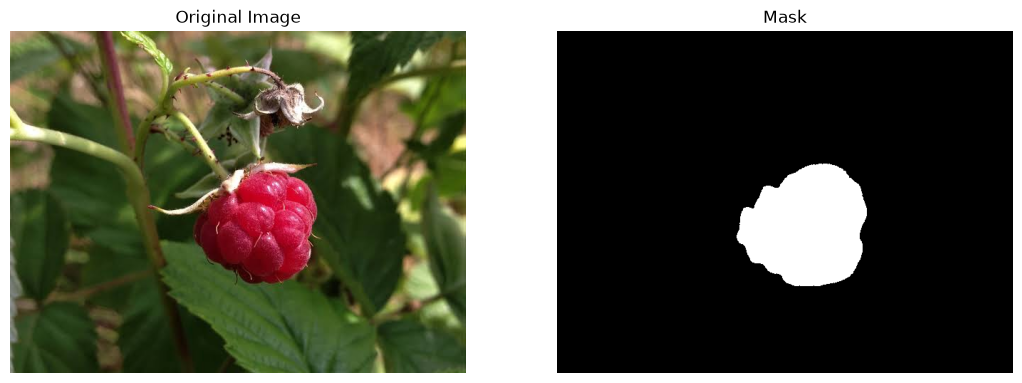

In [8]:
plt.figure(figsize=(20, 10))

plt.subplot(1, 3, 1)
plt.title('Original Image')
plt.imshow(image)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title('Mask')
plt.imshow(inpainting_tool.mask, cmap='gray')
plt.axis('off')

if inpainted_image is not None:
    plt.subplot(1, 3, 3)
    plt.title('Inpainted Image')
    plt.imshow(inpainted_image)
    plt.axis('off')

plt.show()